<a href="https://colab.research.google.com/github/roopeshnakp/animals/blob/main/7_DL_animals10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opendatasets

In [ ]:
import opendatasets as od
import pandas as pd


In [ ]:
od.download('https://www.kaggle.com/datasets/alessiocorrado99/animals10/croissant/download')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username: fghj
Your Kaggle Key: ··········
Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10


100%|██████████| 586M/586M [00:03<00:00, 185MB/s]


In [ ]:
import os

main_dir='/content/animals10/raw-img'
sub_dir= os.listdir(main_dir)
img_exe =('.jpg','.jpeg','.png')

for sub in sub_dir:
  path=os.path.join(main_dir,sub)
  image_count=0
  for filename in os.listdir(path):
    if filename.lower().endswith(img_exe):
      image_count +=1
  print(f'image count {image_count} in folder {sub}')


image count 1820 in folder pecora
image count 2112 in folder farfalla
image count 1668 in folder gatto
image count 1866 in folder mucca
image count 1446 in folder elefante
image count 2623 in folder cavallo
image count 1862 in folder scoiattolo
image count 4863 in folder cane
image count 4821 in folder ragno
image count 3098 in folder gallina


In [ ]:
translate = {"cane": "dog", "cavallo": "horse", "elefante": "elephant", "farfalla": "butterfly", "gallina": "chicken", "gatto": "cat", "mucca": "cow", "pecora": "sheep", "scoiattolo": "squirrel", "dog": "cane", "cavallo": "horse", "elephant" : "elefante", "butterfly": "farfalla", "chicken": "gallina", "cat": "gatto", "cow": "mucca", "spider": "ragno", "squirrel": "scoiattolo"}

In [ ]:
import numpy as np
import cv2
import os
import tensorflow as tf
from keras import regularizers

In [ ]:
x = []
y = []

main_dir = '/content/animals10/raw-img'
sub_dir = os.listdir(main_dir)
img_exe =('.jpg','.jpeg','.png')

for sub in sub_dir:
  path = os.path.join(main_dir,sub)
  for filename in os.listdir(path):
    if filename.lower().endswith(img_exe):
      img = cv2.imread(os.path.join(path,filename))
      img = cv2.resize(img,(48,48))
      x.append(img)
      if sub == 'cane':
        y.append(0)
      elif sub =='cavallo':
        y.append(1)
      elif sub == 'elefante':
        y.append(2)
      elif sub == 'farfalla':
        y.append(3)
      elif sub == 'gallina':
        y.append(4)
      elif sub == 'gatto':
        y.append(5)
      elif sub == 'mucca':
        y.append(6)
      elif sub == 'pecora':
        y.append(7)
      elif sub == 'ragno':
        y.append(8)
      elif sub == 'scoiattolo':
        y.append(9)



In [ ]:
x_np = np.array(x)/255.0
y_np = np.array(y)

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x_np,y_np,test_size=0.2,random_state=42,stratify=y)

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape= (48,48,3)),

    tf.keras.layers.Conv2D(64,(3,3), activation='relu',padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D((2,2)),

    tf.keras.layers.Conv2D(128,(3,3),activation='relu',padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D((2,2)),

    tf.keras.layers.Conv2D(128,(3,3),activation='relu',padding='same'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D((2,2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256,activation='relu',kernel_regularizer=regularizers.l2(0.001)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(128,activation='relu',kernel_regularizer=regularizers.l2(0.001)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(64,activation='relu',kernel_regularizer=regularizers.l2(0.001)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(10,activation='softmax')

])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,448,010 (5.52 MB)

 Trainable params: 1,446,474 (5.52 MB)

 Non-trainable params: 1,536 (6.00 KB)

In [ ]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(x_train,y_train,epochs=20,validation_data=(x_test,y_test))

Epoch 1/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 25s 22ms/step - accuracy: 0.2520 - loss: 3.0779 - val_accuracy: 0.3711 - val_loss: 2.5197
Epoch 2/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.4217 - loss: 2.3171 - val_accuracy: 0.4078 - val_loss: 2.2915
Epoch 3/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5067 - loss: 1.9698 - val_accuracy: 0.4815 - val_loss: 1.9544
Epoch 4/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.5516 - loss: 1.8242 - val_accuracy: 0.5665 - val_loss: 1.7552
Epoch 5/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.5918 - loss: 1.7267 - val_accuracy: 0.6106 - val_loss: 1.6894
Epoch 6/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6212 - loss: 1.6811 - val_accuracy: 0.5535 - val_loss: 1.9007
Epoch 7/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6500 - loss: 1.6471 - val_accuracy: 0.5220 - val_loss: 2.0507
Epoch 8/20
655/655 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6789 - loss: 1.5962 - val_accura

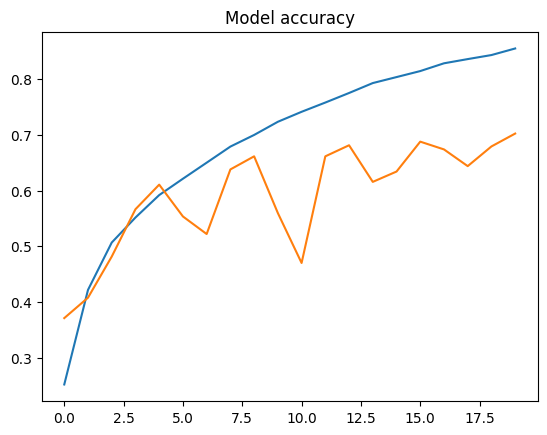

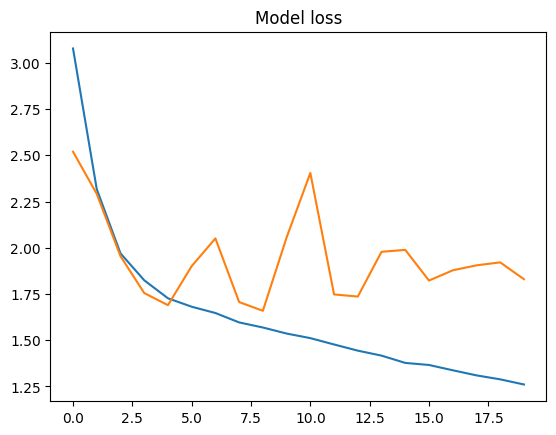

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.show()

In [ ]:
from sklearn.metrics import classification_report

y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred,axis = 1)

print(classification_report(y_pred_classes,y_test))

164/164 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step
              precision    recall  f1-score   support

           0       0.69      0.73      0.71       912
           1       0.76      0.64      0.69       621
           2       0.70      0.55      0.62       367
           3       0.82      0.67      0.74       514
           4       0.77      0.83      0.80       574
           5       0.35      0.74      0.47       159
           6       0.56      0.63      0.59       330
           7       0.59      0.65      0.62       331
           8       0.87      0.77      0.81      1089
           9       0.57      0.63      0.60       339

    accuracy                           0.70      5236
   macro avg       0.67      0.68      0.67      5236
weighted avg       0.72      0.70      0.71      5236



In [ ]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a mapping from class index to animal name
class_names = ['dog', 'horse', 'elephant', 'butterfly', 'chicken', 'cat', 'cow', 'sheep', 'spider', 'squirrel']

uploaded = files.upload()

for filename in uploaded.keys():
    # Read the image
    img_path = filename
    img = cv2.imread(img_path)

    # Check if image was loaded successfully
    if img is None:
        print(f"Error: Could not load image from {img_path}")
        continue

    # Display the original image
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off') # Hide axes ticks and labels
    plt.show()

    # Preprocess the image for model prediction
    img_for_prediction = cv2.resize(img, (48, 48))  # Resize to model input size
    img_for_prediction = img_for_prediction / 255.0               # Normalize pixel values
    img_for_prediction = np.expand_dims(img_for_prediction, axis=0) # Add batch dimension

    # Make a prediction
    prediction = model.predict(img_for_prediction)
    predicted_class_index = np.argmax(prediction)
    predicted_class_name = class_names[predicted_class_index]

    print(f"The uploaded image '{filename}' is predicted to be a: {predicted_class_name}")
